In [1]:
%pylab inline
import gc
import os
import numpy as np
import healpy as hp

import astropy.io.fits as pyfits
import smatch

import matplotlib
from matplotlib.ticker import ScalarFormatter
formatter = ScalarFormatter()
formatter.set_scientific(False)
import matplotlib.pyplot as plt
cm  = plt.cm.get_cmap('RdYlBu')

import sim_analysis_utilities as utilities

dataDir='./.catalog_obs_reGaus_calibrated/fields/'
dataDir16='/work/xiangchong.li/work/S16ACatalogs/S16AStandardCalibrated/field/'
nomDir='./catalog_obs_reGaus_no_m/'

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd wrkDir/s19/s19-1/

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [3]:
def sliding_window_def(snr,res,weights=None,n_gal=100,n_bin_1d=20,snr_overlap=1.4):
    """
    sim_analysis_utilities.sliding_window_def
    
    A routine to define 2d bins in a sample based on its (snr, res)
    using a sliding window.  
    It returns an array of lower and upper bin
    edges for the overlapping SNR bins, each of length n_bin_1d.  It
    also returns resolution bin edges within each SNR bin, i.e., the
    lower and upper resolution bin edges have shape (n_bin_1d,
    n_bin_1d).
    
    Parameters
    n_gal: the minimum number of galaxies in a 2d bin, which 
            determines the overlap in res binning
    n_bin_1d: gives the number of bins to use in 1 dimension.  
    snr_overlap: determines the overlap in snr binning. Set
            snr_overlap=1. does not overlap snr bins
    """
    lower_percentiles = np.linspace(0.,100.,n_bin_1d+1)[:-1]
    delta_perc = lower_percentiles[1]-lower_percentiles[0]
    lower_percentiles -= (0.5*(snr_overlap-1.))*delta_perc
    lower_percentiles[0] = 0
    upper_percentiles = np.linspace(0.,100.,n_bin_1d+1)[1:]
    upper_percentiles += (0.5*(snr_overlap-1.))*delta_perc
    upper_percentiles[-1] = 100.
    snr_lower = utilities.weighted_percentile(snr,lower_percentiles,weights)
    snr_upper = utilities.weighted_percentile(snr,upper_percentiles,weights)
    res_lower = np.zeros((n_bin_1d, n_bin_1d))
    res_upper = np.zeros((n_bin_1d, n_bin_1d))
    # Now loop over the bins in SNR.
    for sbin in range(n_bin_1d):
        sbin_mask   = (snr >= snr_lower[sbin]) & \
            (snr < snr_upper[sbin])
        tmp_res = res[sbin_mask]
        if weights  is not None:
            tmp_wt  =   weights[sbin_mask]
        else:
            tmp_wt  =   None
        if len(tmp_res) < 1.1*n_gal:
            raise RuntimeError("Not enough objects to make "+
                               "sliding window")
        # width of bin in percentiles
        delta_perc  =   100.*max(float(n_gal)/len(tmp_res),1./n_bin_1d)
        bounds_percentiles  =   np.linspace(0.,100.,n_bin_1d+1)
        cent_percentiles    =   (bounds_percentiles[:-1]+bounds_percentiles[1:])/2.
        lower_percentiles   =   cent_percentiles - delta_perc/2.
        upper_percentiles   =   lower_percentiles + delta_perc
        lower_percentiles[0]=   0.
        upper_percentiles[-1]=  100.
        res_lower[sbin, :]  =   utilities.weighted_percentile(tmp_res,
                                    lower_percentiles,tmp_wt)
        res_upper[sbin, :]  =   utilities.weighted_percentile(tmp_res,
                                    upper_percentiles,tmp_wt)
    return snr_lower, snr_upper, res_lower, res_upper

def estimate_pergal_shear(catalog):
    """
    Parameters
    ----------

    catalog: recarray
        Catalog to use for shear estimation.
    """
    # Weights
    if 'i_hsmshaperegauss_derived_weight' in catalog.dtype.names:
        weights =   catalog['i_hsmshaperegauss_derived_weight']
    else:
        weights =   catalog['ishape_hsm_regauss_derived_shape_weight']
    sum_weight  = np.sum(weights)
    # Responsivity
    if 'i_hsmshaperegauss_derived_rms_e' in catalog.dtype.names:
        e_rms   =   catalog['i_hsmshaperegauss_derived_rms_e']
    else:
        e_rms   =   catalog['ishape_hsm_regauss_derived_rms_e']
    resp_num = np.sum(weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight
    if responsivity > 2. or responsivity < 0.:
        raise RuntimeError(
            "Error: responsivity is %f with sum_weight %f"%(responsivity,sum_weight))
    # Multiplicative bias
    if 'i_hsmshaperegauss_derived_shear_bias_m' in catalog.dtype.names:
        model_m=catalog['i_hsmshaperegauss_derived_shear_bias_m']
    else:
        model_m=catalog['ishape_hsm_regauss_derived_shear_bias_m']
    bias_num= np.sum(weights*model_m)
    bias = bias_num / sum_weight

    # Shear
    e1,e2   =   utilities.get_gal_ellip(catalog)
    # Additive bias
    if 'i_hsmshaperegauss_derived_shear_bias_c1' in catalog.dtype.names:
        c1=catalog['i_hsmshaperegauss_derived_shear_bias_c1']
        c2=catalog['i_hsmshaperegauss_derived_shear_bias_c2']
    else:
        c1=catalog['ishape_hsm_regauss_derived_shear_bias_c1']
        c2=catalog['ishape_hsm_regauss_derived_shear_bias_c2']
        
    g1 = e1 / (2.0*responsivity*(1.0+bias)) - c1/((1.0+bias))
    g2 = e2 / (2.0*responsivity*(1.0+bias)) - c2/((1.0+bias))
    return g1, g2, weights

def get_FDFC_flag(ra,dec,version='s19',degree=True):
    # Read fdfc file
    if version=='s16':
        hpfname =   "s16a_wide2_fdfc.fits"
    elif version=='s18':
        hpfname =   "s18a_fdfc_hp_contarea.fits"
    elif version=='s19':
        hpfname =   "s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
    else:
        return np.ones(len(ra),dtype=bool)
    hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
    m       =   hp.read_map(hpfname, nest = True, dtype = np.bool)

    # Get flag
    if degree:
        mfactor =   np.pi/180.
    else:
        mfactor =   1.
    indices_map =   np.where(m)[0]
    nside   =   hp.get_nside(m)
    phi     =   ra*mfactor
    theta   =   np.pi/2. - dec*mfactor
    indices_obj = hp.ang2pix(nside, theta, phi, nest = True)
    return np.in1d(indices_obj, indices_map)

def get_mask_visit_104994(ra,dec):
    def _calDistanceAngle(a1, d1):
        a2=130.43
        d2=-1.02
        a1_f64 = np.array(a1, dtype = np.float64)*np.pi/180.
        d1_f64 = np.array(d1, dtype = np.float64)*np.pi/180.
        a2_f64 = np.array(a2, dtype = np.float64)*np.pi/180.
        d2_f64 = np.array(d2, dtype = np.float64)*np.pi/180.
        return np.arccos(np.cos(d1_f64)*np.cos(d2_f64)*np.cos(a1_f64-a2_f64)+np.sin(d1_f64)*np.sin(d2_f64))/np.pi*180.
    d=_calDistanceAngle(ra,dec)
    mask=(ra>130.5)&(ra<131.5)&(dec<-1.5)
    return (d>0.80)&(~mask)

In [4]:
for fieldname in utilities.field_names:
    data1=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)
    data2=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
    assert(len(data1)==len(data2))
    assert(len(data1['object_id'])==len(data2['object_id']))

-0.0031277868409139956


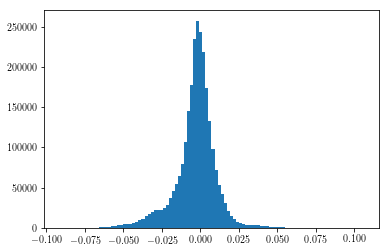

In [5]:
fieldname='XMM'
data2=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
if True:
    data1=pyfits.getdata('anaCat_newS19Mask/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
    match2   =   smatch.match(data1['i_ra'],data1['i_dec'],0.2/3600.,data2['i_ra'],data2['i_dec'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field
    ma=data1['i_hsmshaperegauss_derived_shear_bias_m'][match2['i1']]
    mb=data2['i_hsmshaperegauss_derived_shear_bias_m'][match2['i2']]
    ca1=data1['i_hsmshaperegauss_derived_shear_bias_c1'][match2['i1']]
    cb1=data2['i_hsmshaperegauss_derived_shear_bias_c1'][match2['i2']]
    plt.hist(ma-mb,bins=100)
    print(np.average(ma-mb))

1.9795716177188903e-05


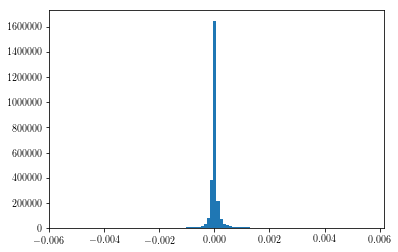

In [8]:
if True:
    plt.hist(ca1-cb1,bins=100)
    print(np.average(ca1-cb1))

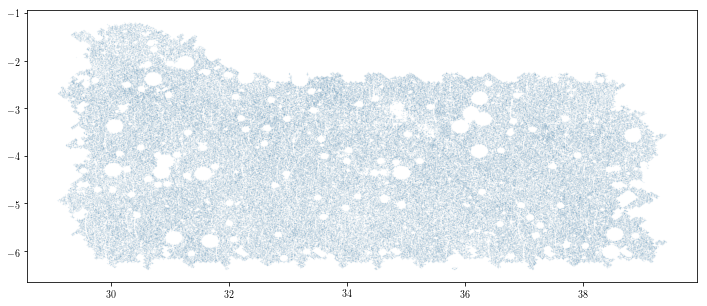

In [7]:
fig=plt.figure(figsize=(12,5))
plt.scatter(data2[0::10]['i_ra'],data2[0::10]['i_dec'],s=0.01,alpha=0.2)

-0.0009232546750250485


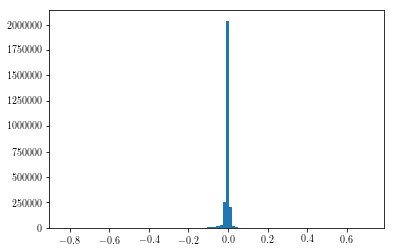

In [37]:
wa=data1['i_hsmshaperegauss_derived_weight'][match2['i1']]
wb=data2['i_hsmshaperegauss_derived_weight'][match2['i2']]
plt.hist(wa-wb,bins=100)
print(np.average(wa-wb)/np.average(wa))

In [ ]:
fieldname='GAMA15H'
data1=pyfits.getdata('anaCat_newS19Mask/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
data2=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
match2   =   smatch.match(data1['i_ra'],data1['i_dec'],0.2/3600.,data2['i_ra'],data2['i_dec'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field

-0.00282577729374318


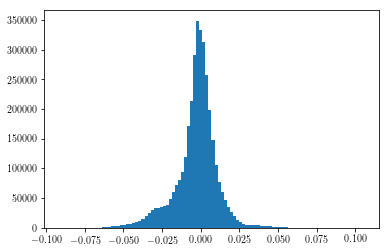

In [19]:
data1[match2['i1']]['i_hsmshaperegauss_derived_shear_bias_m']
ma=data1['i_hsmshaperegauss_derived_shear_bias_m']
mb=data2['i_hsmshaperegauss_derived_shear_bias_m']
ca1=data1['i_hsmshaperegauss_derived_shear_bias_c1']
cb1=data2['i_hsmshaperegauss_derived_shear_bias_c1']
ca2=data1['i_hsmshaperegauss_derived_shear_bias_m']
cb2=data2['i_hsmshaperegauss_derived_shear_bias_m']
ma=ma[match2['i1']]
mb=mb[match2['i2']]
ca1=ca1[match2['i1']]
cb1=cb1[match2['i2']]
ca2=ca2[match2['i1']]
cb2=cb2[match2['i2']]
plt.hist(ma-mb,bins=100)
print(np.average(ma-mb))

3.8982252802597846e-05


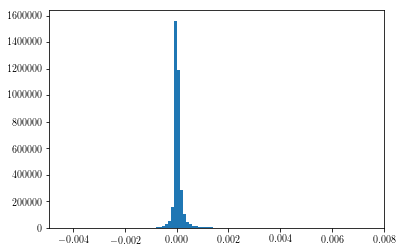

In [20]:
plt.hist(ca1-cb1,bins=100)
print(np.average(ca1-cb1))

In [7]:
fieldname='GAMA09H'
data1=pyfits.getdata('anaCat_newS19Mask/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
data2=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
match2   =   smatch.match(data1['i_ra'],data1['i_dec'],0.2/3600.,data2['i_ra'],data2['i_dec'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field

-0.002792068740894715


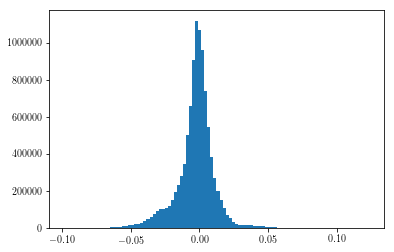

In [8]:
data1[match2['i1']]['i_hsmshaperegauss_derived_shear_bias_m']
ma=data1['i_hsmshaperegauss_derived_shear_bias_m']
mb=data2['i_hsmshaperegauss_derived_shear_bias_m']
ca1=data1['i_hsmshaperegauss_derived_shear_bias_c1']
cb1=data2['i_hsmshaperegauss_derived_shear_bias_c1']
ca2=data1['i_hsmshaperegauss_derived_shear_bias_m']
cb2=data2['i_hsmshaperegauss_derived_shear_bias_m']
ma=ma[match2['i1']]
mb=mb[match2['i2']]
ca1=ca1[match2['i1']]
cb1=cb1[match2['i2']]
ca2=ca2[match2['i1']]
cb2=cb2[match2['i2']]
plt.hist(ma-mb,bins=100)
print(np.average(ma-mb))

3.888933053833741e-05


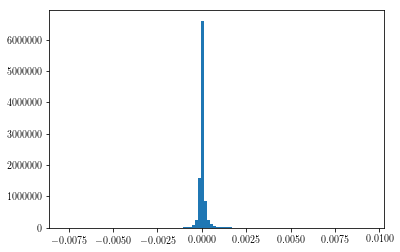

In [9]:
plt.hist(ca1-cb1,bins=100)
print(np.average(ca1-cb1))

In [10]:
fieldname='VVDS'
data1=pyfits.getdata('anaCat_newS19Mask/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
data2=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
match2   =   smatch.match(data1['i_ra'],data1['i_dec'],0.2/3600.,data2['i_ra'],data2['i_dec'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field

-0.003032660941172934


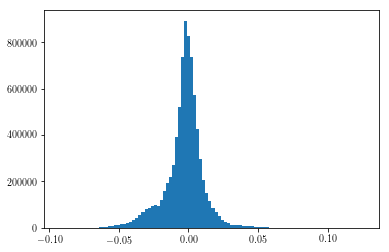

In [11]:
data1[match2['i1']]['i_hsmshaperegauss_derived_shear_bias_m']
ma=data1['i_hsmshaperegauss_derived_shear_bias_m']
mb=data2['i_hsmshaperegauss_derived_shear_bias_m']
ca1=data1['i_hsmshaperegauss_derived_shear_bias_c1']
cb1=data2['i_hsmshaperegauss_derived_shear_bias_c1']
ca2=data1['i_hsmshaperegauss_derived_shear_bias_m']
cb2=data2['i_hsmshaperegauss_derived_shear_bias_m']
ma=ma[match2['i1']]
mb=mb[match2['i2']]
ca1=ca1[match2['i1']]
cb1=cb1[match2['i2']]
ca2=ca2[match2['i1']]
cb2=cb2[match2['i2']]
plt.hist(ma-mb,bins=100)
print(np.average(ma-mb))

4.144249537134612e-05


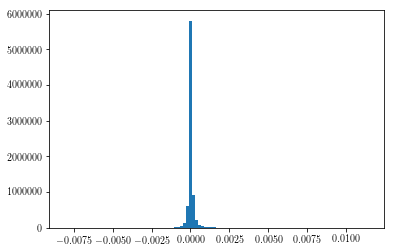

In [12]:
plt.hist(ca1-cb1,bins=100)
print(np.average(ca1-cb1))

In [13]:
fieldname='XMM'
data1=pyfits.getdata('anaCat_newS19Mask/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
data2=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
match2   =   smatch.match(data1['i_ra'],data1['i_dec'],0.2/3600.,data2['i_ra'],data2['i_dec'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field

-0.0031277868409139956


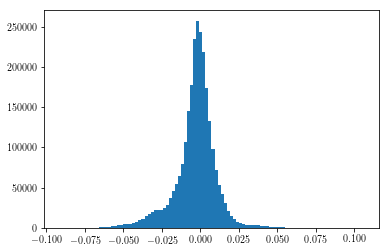

In [14]:
data1[match2['i1']]['i_hsmshaperegauss_derived_shear_bias_m']
ma=data1['i_hsmshaperegauss_derived_shear_bias_m']
mb=data2['i_hsmshaperegauss_derived_shear_bias_m']
ca1=data1['i_hsmshaperegauss_derived_shear_bias_c1']
cb1=data2['i_hsmshaperegauss_derived_shear_bias_c1']
ca2=data1['i_hsmshaperegauss_derived_shear_bias_m']
cb2=data2['i_hsmshaperegauss_derived_shear_bias_m']
ma=ma[match2['i1']]
mb=mb[match2['i2']]
ca1=ca1[match2['i1']]
cb1=cb1[match2['i2']]
ca2=ca2[match2['i1']]
cb2=cb2[match2['i2']]
plt.hist(ma-mb,bins=100)
print(np.average(ma-mb))

1.9795716177188903e-05


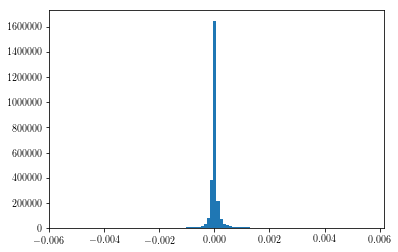

In [15]:
plt.hist(ca1-cb1,bins=100)
print(np.average(ca1-cb1))

In [16]:
fieldname='HECTOMAP'
data1=pyfits.getdata('anaCat_newS19Mask/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
data2=pyfits.getdata('anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_calibrated/%s_calibrated.fits' %fieldname)
match2   =   smatch.match(data1['i_ra'],data1['i_dec'],0.2/3600.,data2['i_ra'],data2['i_dec'],maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field

-0.0025777771784554547


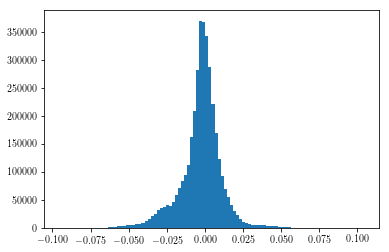

In [17]:
data1[match2['i1']]['i_hsmshaperegauss_derived_shear_bias_m']
ma=data1['i_hsmshaperegauss_derived_shear_bias_m']
mb=data2['i_hsmshaperegauss_derived_shear_bias_m']
ca1=data1['i_hsmshaperegauss_derived_shear_bias_c1']
cb1=data2['i_hsmshaperegauss_derived_shear_bias_c1']
ca2=data1['i_hsmshaperegauss_derived_shear_bias_m']
cb2=data2['i_hsmshaperegauss_derived_shear_bias_m']
ma=ma[match2['i1']]
mb=mb[match2['i2']]
ca1=ca1[match2['i1']]
cb1=cb1[match2['i2']]
ca2=ca2[match2['i1']]
cb2=cb2[match2['i2']]
plt.hist(ma-mb,bins=100)
print(np.average(ma-mb))

-1.1602867503741448e-05


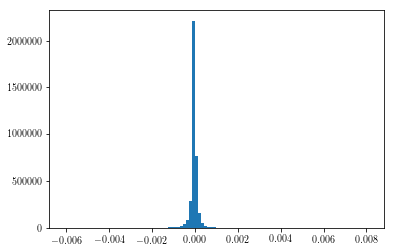

In [18]:
plt.hist(ca1-cb1,bins=100)
print(np.average(ca1-cb1))